In [47]:
from sgt import SGT

import numpy as np
import pandas as pd
from itertools import chain
from itertools import product as iterproduct
import warnings

import pickle

########
from sklearn.preprocessing import LabelEncoder
import tensorflow as tf
from keras.datasets import imdb
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense
from tensorflow.keras.layers import LSTM
from tensorflow.keras.layers import Dropout
from tensorflow.keras.layers import Activation
from tensorflow.keras.layers import Flatten
from tensorflow.keras.layers import Embedding
from tensorflow.keras.preprocessing import sequence

from sklearn.model_selection import train_test_split
from sklearn.model_selection import KFold
from sklearn.model_selection import StratifiedKFold
import sklearn.metrics
from sklearn.metrics import f1_score, precision_score, recall_score, confusion_matrix
import time

from sklearn.decomposition import PCA
from sklearn.cluster import KMeans

import matplotlib.pyplot as plt
%matplotlib inline

np.random.seed(7) # fix random seed for reproducibility

from keras.models import Model
from keras.regularizers import l2
from keras.constraints import max_norm
from keras.utils import to_categorical
from keras.preprocessing.text import Tokenizer
from keras_preprocessing.sequence import pad_sequences
from keras.callbacks import EarlyStopping
from keras.layers import Input, Dense, Dropout, Flatten, Activation
from keras.layers import Conv1D, Add, MaxPooling1D, BatchNormalization
from keras.layers import Embedding, Bidirectional, CuDNNLSTM, GlobalMaxPooling1D


In [2]:
df_train = pd.read_csv('TrainDataSet.csv',low_memory=False)
#df_train['S-Protein'] = df_train['S-Protein'].astype(np.float32)
df_train.dtypes

Identifier         object
S-Protein          object
Classification     object
Unnamed: 3        float64
dtype: object

In [3]:
df_train = df_train.drop(columns=['Unnamed: 3'])
list(df_train.columns)

['Identifier', 'S-Protein', 'Classification']

In [4]:
df_train=df_train.dropna()
df_train.shape

(104, 3)

In [5]:
df_train = df_train.replace('\n','', regex=True)
df_train['S-Protein'] = df_train['S-Protein'].str.strip(r'\\r')
print (df_train)

      Identifier                                          S-Protein  \
0    NC_045512.2  MFVFLVLLPLVSSQCVNLTTRTQLPPAYTNSFTRGVYYPDKVFRSS...   
1       MZ437368  MFVFLVLLPLVSSQCVNLRTRTQLPPAYTNSFTRGVYYPDKVFRSS...   
2       OM570262  MFVFLVLLPLVSSQCVNLTTRTQLPPAYTNSFTRGVYYPDKVFRSS...   
3       QHR84449  MFVFLVLLPLVSSQCVNLTTRTQLPPAYTNSFTRGVYYPDKVFRSS...   
4     QIX07431.1  MFVFLVLLPLVSSQCVNLTTRTQLPPAYTNSFTRGVYYPDKVFRSS...   
..           ...                                                ...   
99    UST22952.1  MFVFLVLLPLVSSQCVNLITRTQSYTNSFTRGVYYPDKVFRSSVLH...   
100   QQV24132.1  MFVFLVLLPLVSSQCVNLTTRTQLPPAYTNSFTRGVYYPDKVFRSS...   
101   QQV24885.1  MFVFLVLLPLVSSQCVNLTTRTQLPPAYTNSFTRGVYYPDKVFRSS...   
102   QQV24803.1  MFVFLVLLPLVSSQCVNLTTRTQLPPAYTNSFTRGVYYPDKVFRSS...   
103   QQV26579.1  MFVFLVLLPLVSSQCVNLTTRTQLPPAYTNSFTRGVYYPDKVFRSS...   

    Classification  
0          Regular  
1          Concern  
2          Concern  
3          Regular  
4          Regular  
..             ...  


In [6]:
#df_train = df_train.set_index('Identifier')
df_train

,Identifier,S-Protein,Classification
0,NC_045512.2,MFVFLVLLPLVSSQCVNLTTRTQLPPAYTNSFTRGVYYPDKVFRSS...,Regular
1,MZ437368,MFVFLVLLPLVSSQCVNLRTRTQLPPAYTNSFTRGVYYPDKVFRSS...,Concern
2,OM570262,MFVFLVLLPLVSSQCVNLTTRTQLPPAYTNSFTRGVYYPDKVFRSS...,Concern
3,QHR84449,MFVFLVLLPLVSSQCVNLTTRTQLPPAYTNSFTRGVYYPDKVFRSS...,Regular
4,QIX07431.1,MFVFLVLLPLVSSQCVNLTTRTQLPPAYTNSFTRGVYYPDKVFRSS...,Regular
...,...,...,...
99,UST22952.1,MFVFLVLLPLVSSQCVNLITRTQSYTNSFTRGVYYPDKVFRSSVLH...,Regular
100,QQV24132.1,MFVFLVLLPLVSSQCVNLTTRTQLPPAYTNSFTRGVYYPDKVFRSS...,Regular
101,QQV24885.1,MFVFLVLLPLVSSQCVNLTTRTQLPPAYTNSFTRGVYYPDKVFRSS...,Regular
102,QQV24803.1,MFVFLVLLPLVSSQCVNLTTRTQLPPAYTNSFTRGVYYPDKVFRSS...,Regular


In [7]:
y = df_train['Classification']
encoder = LabelEncoder()
encoder.fit(y)
y = encoder.transform(y)
encoder_name_mapping_y = dict(zip(encoder.classes_, encoder.transform(encoder.classes_)))
print(encoder_name_mapping_y)

{'Concern': 0, 'Regular': 1}


In [8]:
y

array([1, 0, 0, 1, 1, 0, 0, 0, 1, 0, 0, 0, 1, 1, 1, 1, 1, 1, 1, 0, 0, 1,
       0, 0, 1, 1, 0, 0, 0, 1, 1, 1, 0, 0, 1, 0, 1, 1, 1, 0, 1, 0, 0, 0,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 0, 1, 1, 0, 0, 0, 0, 0, 0, 0, 1, 1, 1, 1, 1])

In [9]:
X = df_train['S-Protein'].apply(str)
def split(word): 
    return [char for char in word]
sequences = [split(x) for x in X]
print(sequences[0])

['M', 'F', 'V', 'F', 'L', 'V', 'L', 'L', 'P', 'L', 'V', 'S', 'S', 'Q', 'C', 'V', 'N', 'L', 'T', 'T', 'R', 'T', 'Q', 'L', 'P', 'P', 'A', 'Y', 'T', 'N', 'S', 'F', 'T', 'R', 'G', 'V', 'Y', 'Y', 'P', 'D', 'K', 'V', 'F', 'R', 'S', 'S', 'V', 'L', 'H', 'S', 'T', 'Q', 'D', 'L', 'F', 'L', 'P', 'F', 'F', 'S', 'N', 'V', 'T', 'W', 'F', 'H', 'A', 'I', 'H', 'V', 'S', 'G', 'T', 'N', 'G', 'T', 'K', 'R', 'F', 'D', 'N', 'P', 'V', 'L', 'P', 'F', 'N', 'D', 'G', 'V', 'Y', 'F', 'A', 'S', 'T', 'E', 'K', 'S', 'N', 'I', 'I', 'R', 'G', 'W', 'I', 'F', 'G', 'T', 'T', 'L', 'D', 'S', 'K', 'T', 'Q', 'S', 'L', 'L', 'I', 'V', 'N', 'N', 'A', 'T', 'N', 'V', 'V', 'I', 'K', 'V', 'C', 'E', 'F', 'Q', 'F', 'C', 'N', 'D', 'P', 'F', 'L', 'G', 'V', 'Y', 'Y', 'H', 'K', 'N', 'N', 'K', 'S', 'W', 'M', 'E', 'S', 'E', 'F', 'R', 'V', 'Y', 'S', 'S', 'A', 'N', 'N', 'C', 'T', 'F', 'E', 'Y', 'V', 'S', 'Q', 'P', 'F', 'L', 'M', 'D', 'L', 'E', 'G', 'K', 'Q', 'G', 'N', 'F', 'K', 'N', 'L', 'R', 'E', 'F', 'V', 'F', 'K', 'N', 'I', 'D', 'G', 'Y',

In [10]:
id = df_train['Identifier'].apply(str).tolist()
#corpus = pd.DataFrame(sequences)
corpus = pd.DataFrame(
    {'id': id,
     'sequence': sequences,
    })
corpus = corpus.dropna(axis=1)
corpus = corpus.reset_index(drop=True) 
corpus

,id,sequence
0,NC_045512.2,"[M, F, V, F, L, V, L, L, P, L, V, S, S, Q, C, ..."
1,MZ437368,"[M, F, V, F, L, V, L, L, P, L, V, S, S, Q, C, ..."
2,OM570262,"[M, F, V, F, L, V, L, L, P, L, V, S, S, Q, C, ..."
3,QHR84449,"[M, F, V, F, L, V, L, L, P, L, V, S, S, Q, C, ..."
4,QIX07431.1,"[M, F, V, F, L, V, L, L, P, L, V, S, S, Q, C, ..."
...,...,...
99,UST22952.1,"[M, F, V, F, L, V, L, L, P, L, V, S, S, Q, C, ..."
100,QQV24132.1,"[M, F, V, F, L, V, L, L, P, L, V, S, S, Q, C, ..."
101,QQV24885.1,"[M, F, V, F, L, V, L, L, P, L, V, S, S, Q, C, ..."
102,QQV24803.1,"[M, F, V, F, L, V, L, L, P, L, V, S, S, Q, C, ..."


In [11]:
embedding = corpus.set_index('id')
embedding

,sequence
id,
NC_045512.2,"[M, F, V, F, L, V, L, L, P, L, V, S, S, Q, C, ..."
MZ437368,"[M, F, V, F, L, V, L, L, P, L, V, S, S, Q, C, ..."
OM570262,"[M, F, V, F, L, V, L, L, P, L, V, S, S, Q, C, ..."
QHR84449,"[M, F, V, F, L, V, L, L, P, L, V, S, S, Q, C, ..."
QIX07431.1,"[M, F, V, F, L, V, L, L, P, L, V, S, S, Q, C, ..."
...,...
UST22952.1,"[M, F, V, F, L, V, L, L, P, L, V, S, S, Q, C, ..."
QQV24132.1,"[M, F, V, F, L, V, L, L, P, L, V, S, S, Q, C, ..."
QQV24885.1,"[M, F, V, F, L, V, L, L, P, L, V, S, S, Q, C, ..."


In [12]:
# https://dmnfarrell.github.io/bioinformatics/mhclearning
# http://www.cryst.bbk.ac.uk/education/AminoAcid/the_twenty.html
# 1 letter code for 20 natural amino acids

codes = ['A', 'C', 'D', 'E', 'F', 'G', 'H', 'I', 'K', 'L',
         'M', 'N', 'P', 'Q', 'R', 'S', 'T', 'V', 'W', 'X','Y']

def create_dict(codes):
  char_dict = {}
  for index, val in enumerate(codes):
    char_dict[val] = index+1

  return char_dict

char_dict = create_dict(codes)

print(char_dict)
print("Dict Length:", len(char_dict))

{'A': 1, 'C': 2, 'D': 3, 'E': 4, 'F': 5, 'G': 6, 'H': 7, 'I': 8, 'K': 9, 'L': 10, 'M': 11, 'N': 12, 'P': 13, 'Q': 14, 'R': 15, 'S': 16, 'T': 17, 'V': 18, 'W': 19, 'X': 20, 'Y': 21}
Dict Length: 21


In [13]:
def integer_encoding(data):
  """
  - Encodes code sequence to integer values.
 20 Amino Acids + 1 X for Unknown
  """
  
  encode_list = []
  for row in embedding['sequence'].values:
    row_encode = []
    for code in row:
      row_encode.append(char_dict.get(code, 0))
    encode_list.append(np.array(row_encode))
  
  return encode_list


In [14]:
train_encode = integer_encoding(embedding) 
train_encode

[array([11,  5, 18, ...,  7, 21, 17]),
 array([11,  5, 18, ...,  7, 21, 17]),
 array([11,  5, 18, ...,  7, 21, 17]),
 array([11,  5, 18, ...,  7, 21, 17]),
 array([11,  5, 18, ...,  7, 21, 17]),
 array([11,  5, 18, ...,  7, 21, 17]),
 array([11,  5, 18, ...,  7, 21, 17]),
 array([11,  5, 18, ...,  7, 21, 17]),
 array([11,  5, 18, ...,  7, 21, 17]),
 array([11,  5, 18, ...,  7, 21, 17]),
 array([11,  5, 18, ...,  7, 21, 17]),
 array([11,  5, 18, ...,  7, 21, 17]),
 array([11,  5, 18, ...,  7, 21, 17]),
 array([11,  5, 18, ...,  7, 21, 17]),
 array([11,  5, 18, ...,  7, 21, 17]),
 array([11,  5, 18, ...,  7, 21, 17]),
 array([11,  5, 18, ...,  7, 21, 17]),
 array([11,  5, 18, ...,  7, 21, 17]),
 array([11,  5, 18, ...,  7, 21, 17]),
 array([11,  5, 18, ...,  7, 21, 17]),
 array([11,  5, 18, ...,  7, 21, 17]),
 array([11,  5, 18, ...,  7, 21, 17]),
 array([11,  5, 18, ...,  7, 21, 17]),
 array([11,  5, 18, ...,  7, 21, 17]),
 array([11,  5, 18, ...,  7, 21, 17]),
 array([11,  5, 18, ..., 

In [15]:
# padding sequences
max_length = 1273
train_pad = pad_sequences(train_encode, maxlen=max_length, padding='post', truncating='post')
train_pad.shape

(104, 1273)

In [16]:
train_ohe = to_categorical(train_pad)
train_ohe.shape

(104, 1273, 22)

In [17]:
# One hot encoding of outputs
y_train = to_categorical(y)
y_train.shape

(104, 2)

In [26]:
x_input = Input(shape=(1273,))
emb = Embedding(22, 128, input_length=max_length)(x_input)
bi_rnn = Bidirectional(LSTM(64, kernel_regularizer=l2(0.01), recurrent_regularizer=l2(0.01), bias_regularizer=l2(0.01)))(emb)
x = Dropout(0.3)(bi_rnn)

# sigmoid classifier
x_output = Dense(2, activation='sigmoid')(x)

model1 = Model(inputs=x_input, outputs=x_output)
model1.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])

model1.summary()

Model: "model_1"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 input_2 (InputLayer)        [(None, 1273)]            0         
                                                                 
 embedding_1 (Embedding)     (None, 1273, 128)         2816      
                                                                 
 bidirectional_1 (Bidirectio  (None, 128)              98816     
 nal)                                                            
                                                                 
 dropout_1 (Dropout)         (None, 128)               0         
                                                                 
 dense_1 (Dense)             (None, 2)                 258       
                                                                 
Total params: 101,890
Trainable params: 101,890
Non-trainable params: 0
_____________________________________________________

In [27]:
# Early Stopping
es = EarlyStopping(monitor='val_loss', patience=3, verbose=1)

In [28]:
#Check with Test Data
df_test = pd.read_csv('TestDataSetActuals.csv',low_memory=False)
df_test = df_test.drop(columns=['Unnamed: 3'])
df_test = df_test.replace('\n','', regex=True)
df_test['S-Protein'] = df_test['S-Protein'].str.strip(r'\\r')
X_test = df_test['S-Protein'].apply(str)
test_sequences = [split(x) for x in X_test]
 
identifier2=df_test['Identifier'].apply(str).tolist()
corpus_new = pd.DataFrame(
    {'id': identifier2,
     'sequence': test_sequences,
    })
corpus_new = corpus_new.dropna(axis=1)
corpus_new = corpus_new.reset_index(drop=True)
corpus_new = corpus_new.set_index('id')
corpus_new

,sequence
id,
OR575624.1,"[M, F, V, F, L, V, L, L, P, L, V, S, S, Q, C, ..."
UJK14488.1,"[M, F, V, F, L, V, L, L, P, L, V, S, S, Q, C, ..."
QTZ19244.1,"[M, F, V, F, L, V, L, L, P, L, V, S, S, Q, C, ..."
WBQ65914.2,"[M, F, V, F, L, V, L, L, P, L, V, S, S, Q, C, ..."
QZQ30931.1,"[M, F, V, F, L, V, L, L, P, L, V, S, S, Q, C, ..."
QZQ31266.1,"[M, F, V, F, L, V, L, L, P, L, V, S, S, Q, C, ..."
QZQ31201.1,"[M, F, V, F, L, V, L, L, P, L, V, S, S, Q, C, ..."
QZQ31904.1,"[M, F, V, F, L, V, L, L, P, L, V, S, S, Q, C, ..."
QZQ31816.1,"[M, F, V, F, L, V, L, L, P, L, V, S, S, Q, C, ..."


In [29]:
def integer_encoding(data):
  """
  - Encodes code sequence to integer values.
 20 Amino Acids + 1 X for Unknown
  """
  
  encode_list = []
  for row in corpus_new['sequence'].values:
    row_encode = []
    for code in row:
      row_encode.append(char_dict.get(code, 0))
    encode_list.append(np.array(row_encode))
  
  return encode_list

test_encode = integer_encoding(corpus_new) 
test_encode

[array([11,  5, 18, ...,  7, 21, 17]),
 array([11,  5, 18, ...,  7, 21, 17]),
 array([11,  5, 18, ...,  7, 21, 17]),
 array([11,  5, 18, ...,  7, 21, 17]),
 array([11,  5, 18, ...,  7, 21, 17]),
 array([11,  5, 18, ...,  7, 21, 17]),
 array([11,  5, 18, ...,  7, 21, 17]),
 array([11,  5, 18, ...,  7, 21, 17]),
 array([11,  5, 18, ...,  7, 21, 17]),
 array([11,  5, 18, ...,  7, 21, 17]),
 array([11,  5, 18, ...,  7, 21, 17])]

In [30]:
val_pad = pad_sequences(test_encode, maxlen=max_length, padding='post', truncating='post')
val_pad.shape

(11, 1273)

In [31]:
y_test = df_test['Classification']
encoder = LabelEncoder()
encoder.fit(y_test)
y_test = encoder.transform(y_test)
encoder_name_mapping_y = dict(zip(encoder.classes_, encoder.transform(encoder.classes_)))
print(encoder_name_mapping_y)

{'Concern': 0, 'Regular': 1}


In [32]:
# One hot encoding of outputs
y_test = to_categorical(y_test)
y_test.shape

(11, 2)

In [33]:
history1 = model1.fit(
    train_pad, y_train,
    epochs=100, batch_size=10,
    validation_data=(val_pad, y_test),
    callbacks=[es]
    )

Epoch 1/100
11/11 [==============================] - 4s 228ms/step - loss: 6.1299 - accuracy: 0.7212 - val_loss: 5.4814 - val_accuracy: 0.6364
Epoch 2/100
11/11 [==============================] - 2s 192ms/step - loss: 5.0314 - accuracy: 0.7115 - val_loss: 4.5453 - val_accuracy: 0.6364
Epoch 3/100
11/11 [==============================] - 2s 189ms/step - loss: 4.1657 - accuracy: 0.7115 - val_loss: 3.8345 - val_accuracy: 0.6364
Epoch 4/100
11/11 [==============================] - 2s 192ms/step - loss: 3.5289 - accuracy: 0.7115 - val_loss: 3.2872 - val_accuracy: 0.6364
Epoch 5/100
11/11 [==============================] - 2s 199ms/step - loss: 3.0322 - accuracy: 0.7115 - val_loss: 2.8672 - val_accuracy: 0.6364
Epoch 6/100
11/11 [==============================] - 2s 213ms/step - loss: 2.6557 - accuracy: 0.7115 - val_loss: 2.5513 - val_accuracy: 0.6364
Epoch 7/100
11/11 [==============================] - 2s 196ms/step - loss: 2.3659 - accuracy: 0.7115 - val_loss: 2.3145 - val_accuracy: 0.6364

Epoch 58/100
11/11 [==============================] - 2s 193ms/step - loss: 0.7544 - accuracy: 0.9038 - val_loss: 0.7598 - val_accuracy: 0.9091
Epoch 59/100
11/11 [==============================] - 2s 201ms/step - loss: 0.7377 - accuracy: 0.8269 - val_loss: 0.7504 - val_accuracy: 0.9091
Epoch 60/100
11/11 [==============================] - 2s 193ms/step - loss: 0.7201 - accuracy: 0.9038 - val_loss: 0.7331 - val_accuracy: 0.9091
Epoch 61/100
11/11 [==============================] - 2s 198ms/step - loss: 0.7076 - accuracy: 0.8750 - val_loss: 0.7178 - val_accuracy: 0.9091
Epoch 62/100
11/11 [==============================] - 2s 199ms/step - loss: 0.7056 - accuracy: 0.9038 - val_loss: 0.7108 - val_accuracy: 0.9091
Epoch 63/100
11/11 [==============================] - 2s 194ms/step - loss: 0.7128 - accuracy: 0.8558 - val_loss: 0.6965 - val_accuracy: 0.9091
Epoch 64/100
11/11 [==============================] - 2s 193ms/step - loss: 0.6966 - accuracy: 0.9038 - val_loss: 0.6942 - val_accuracy:

dict_keys(['loss', 'accuracy', 'val_loss', 'val_accuracy'])


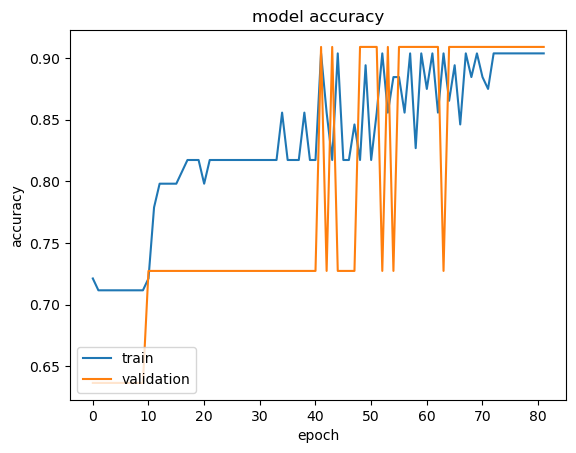

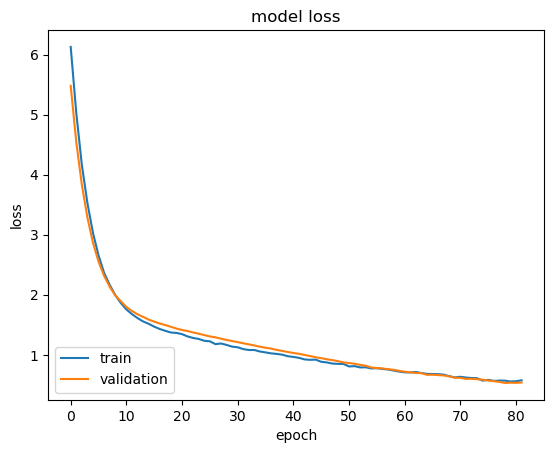

In [35]:
print(history1.history.keys())
# summarize history for accuracy
plt.plot(history1.history['accuracy'])
plt.plot(history1.history['val_accuracy'])
plt.title('model accuracy')
plt.ylabel('accuracy')
plt.xlabel('epoch')
plt.legend(['train', 'validation'], loc='lower left')
plt.show()
# summarize history for loss
plt.plot(history1.history['loss'])
plt.plot(history1.history['val_loss'])
plt.title('model loss')
plt.ylabel('loss')
plt.xlabel('epoch')
plt.legend(['train', 'validation'], loc='lower left')
plt.show()

In [38]:
y_new = model1.predict(val_pad)
# show the inputs and predicted outputs
for i in range(len(y_new)):
 print("identifier=%s, Predicted=%s" % (id[i], y_new[i]))

1/1 [==============================] - 0s 375ms/step
identifier=NC_045512.2, Predicted=[0.7592694  0.25189382]
identifier=MZ437368, Predicted=[0.7592699 0.2518934]
identifier=OM570262, Predicted=[0.18995066 0.8048373 ]
identifier=QHR84449, Predicted=[0.9896294  0.01113676]
identifier=QIX07431.1, Predicted=[0.17175478 0.83015597]
identifier=UUT42029.1, Predicted=[0.17175478 0.83015597]
identifier=QTZ19280.1, Predicted=[0.17175478 0.83015597]
identifier=QTZ19268.1, Predicted=[0.17175478 0.83015597]
identifier=QIZ97051.1, Predicted=[0.17175478 0.83015597]
identifier=WEF91819.2, Predicted=[0.17175478 0.83015597]
identifier=WEF85329.2, Predicted=[0.17175478 0.83015597]


In [43]:
def display_model_score(model, train, val, batch_size):

  train_score = model.evaluate(train[0], train[1], batch_size=batch_size, verbose=1)
  print('Train loss: ', train_score[0])
  print('Train accuracy: ', train_score[1])
  print('-'*70)

  val_score = model.evaluate(val[0], val[1], batch_size=batch_size, verbose=1)
  print('Val loss: ', val_score[0])
  print('Val accuracy: ', val_score[1])
  print('-'*70)
  

In [44]:
display_model_score(model1,
    [train_pad, y_train],
    [val_pad, y_test],
    256)

1/1 [==============================] - 0s 462ms/step - loss: 0.5436 - accuracy: 0.9038
Train loss:  0.5435816049575806
Train accuracy:  0.9038461446762085
----------------------------------------------------------------------
1/1 [==============================] - 0s 60ms/step - loss: 0.5371 - accuracy: 0.9091
Val loss:  0.5371435880661011
Val accuracy:  0.9090909361839294
----------------------------------------------------------------------
